In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df=pd.read_csv('uber.csv')

In [ ]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [ ]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [ ]:
df=df.dropna()

In [ ]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [ ]:
df["distance"]=(
    ((df['dropoff_latitude']-df['pickup_latitude'])**2+(df['dropoff_longitude']- df['pickup_longitude'])**2)**0.5
)

In [ ]:
df = df[(df['fare_amount']>0) & (df['fare_amount']<100)]
df = df[df['distance']<50]

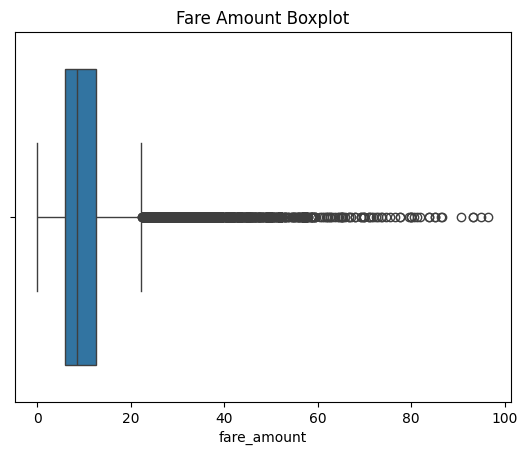

In [ ]:
sns.boxplot(x=df['fare_amount'])
plt.title('Fare Amount Boxplot')
plt.show()

In [ ]:
df['pickup_datetime']= pd.to_datetime(df['pickup_datetime'])
df['pickup_hour']=df['pickup_datetime'].dt.hour
df['pickup_week']=df['pickup_datetime'].dt.dayofweek

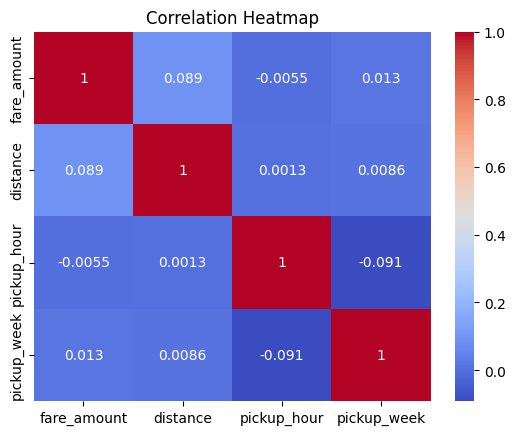

In [ ]:
corr= df[['fare_amount', 'distance', 'pickup_hour', 'pickup_week']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
X=df[['distance', 'pickup_hour', 'pickup_week']]
y=df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [ ]:
rf=RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf=rf.predict(X_test)


In [ ]:
# Linear Regression Evaluation
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results:")
print("R2 Score:", round(r2_lr, 4))
print("RMSE:", round(rmse_lr, 4))


Linear Regression Results:
R2 Score: 0.0128
RMSE: 9.15


In [ ]:
# Random Forest Regression Evaluation
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Results:")
print("R2 Score:", round(r2_rf, 4))
print("RMSE:", round(rmse_rf, 4))

Random Forest Regression Results:
R2 Score: 0.7421
RMSE: 4.6766
